In [163]:
import numpy as np
import matplotlib.pyplot as plt
import math

In [164]:
def f_normal(x):
  return 2*np.exp(-(x**2)/2)/np.sqrt(2*np.pi)

def g_normal(x):
  return np.exp(-x)

def normal(mi, sigma, M):
  c = 2*np.exp(1/2)/np.sqrt(2*np.pi)
  amostra = []
  while len(amostra) < M:
    u = np.random.uniform()
    y = (-1) * np.log(np.random.uniform())

    if(u < f_normal(y)/(c*g_normal(y))):
      amostra.append(y)

  for i in range(len(amostra)):
    if(np.random.uniform() < 0.5):
      amostra[i] = -amostra[i]

  if(mi != 0 or sigma != 1):
    for i in range(len(amostra)):
      amostra[i] = (amostra[i] * sigma) + mi

  return amostra


Item (a)

In [165]:
delta_t = 0.01
def simulacao(x, y, M):
    resultados = []
    x_vetor = []
    y_vetor = []
    for i in range(M):
        x_n = [x]
        y_n = [y]
        x0 = x
        y0 = y
        M = 0
        while x0**2 + y0**2 < 1:
            z1 = delta_t**0.5 * normal(0, 1, 1)[0]
            z2 = delta_t**0.5 * normal(0, 1, 1)[0]

            x0 += z1
            y0 += z2
            if((x0)**2 + (y0)**2 > 1):
                norma = (x0**2 + y0**2)**0.5
                x0 = x0/norma
                y0 = y0/norma
                x_n.append(x0)
                y_n.append(y0)

            else:
                x_n.append(x0)
                y_n.append(y0)
                
        if(x0 > 0):
            resultados.append(1)
        else:
            resultados.append(0)
        x_vetor.append(x_n)
        y_vetor.append(y_n)
    return [np.mean(resultados), x_vetor, y_vetor]


In [166]:
delta_t = 0.01
valor_1 = simulacao(0, 0, 1_000)[0]
valor_2 = simulacao(0.3, 0, 1_000)[0]
valor_3 = simulacao(0.7, 0, 1_000)[0]

print(f"Para (0,0), Valor obtido: {valor_1}")
print(f"Para (0.3,0), Valor obtido: {valor_2}")
print(f"Para (0.7,0), Valor obtido: {valor_3}")

Para (0,0), Valor obtido: 0.519
Para (0.3,0), Valor obtido: 0.647
Para (0.7,0), Valor obtido: 0.875


Item (b)

Item (c)

In [167]:
print(f"Para (0,0), Valor obtido: {valor_1}, valor teorico: 0.5, diferença {valor_1 - 0.5}")
print(f"Para (0.3,0), Valor obtido: {valor_2}, valor teorico: 0.686, diferença {valor_2-0.686}")
print(f"Para (0.7,0), Valor obtido: {valor_3}, valor teorico: 0.889, diferença {valor_3-0.889}")

Para (0,0), Valor obtido: 0.519, valor teorico: 0.5, diferença 0.019000000000000017
Para (0.3,0), Valor obtido: 0.647, valor teorico: 0.686, diferença -0.039000000000000035
Para (0.7,0), Valor obtido: 0.875, valor teorico: 0.889, diferença -0.014000000000000012


Item (d)

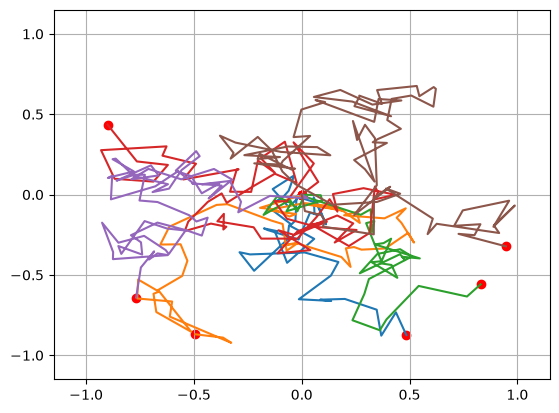

In [168]:
u1 = simulacao(0, 0, 6)

pontos_x = []
pontos_y = []

for i in range(len(u1[1])):
    pontos_x.append(u1[1][i][0])
    pontos_x.append(u1[1][i][-1])

    pontos_y.append(u1[2][i][0])
    pontos_y.append(u1[2][i][-1])

    plt.plot(u1[1][i], u1[2][i])

plt.scatter(pontos_x, pontos_y, color="red")

plt.xlim(-1.15, 1.15)
plt.ylim(-1.15, 1.15)

plt.grid(True)
plt.show()